# 01 — Measurements by Water Type and Decade

Produces **Figure 7**: estimated number of measurements by water category and decade for the continental US, for all tables with a date associated.

Requires `data/analysis/table_level_metadata_published.csv` (the LLM-processed publication subset, produced by `filter_published_tables.py`). This is one row per digitized table — using it avoids the page-level double-counting that inflated earlier versions of this figure.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from pathlib import Path
import sys
sys.path.insert(0, str(Path('.')))   # so water_palette imports cleanly
from water_palette import CATEGORY_ORDER, get_color_for
from paper_filters import drop_tribal
from date_parsing import FALLBACK_STATUSES

root         = Path('../..')
table_path   = root / 'data/analysis/table_level_metadata_published.csv'
figures_path = root / 'manuscript/figures'
figures_path.mkdir(parents=True, exist_ok=True)

df = pd.read_csv(table_path)
print(f'Loaded {len(df):,} table rows')
# tribal pages are withheld from paper figures and statistics (paper_filters.py)
df = drop_tribal(df, id_col='doc_id')
# decades come from table-level dates (date_parsing.apply_table_dates); undated tables drop out below
print(df['date_status'].value_counts().to_string())

C:\Users\aeliz\AppData\Local\Temp\ipykernel_12088\782098933.py:17: DtypeWarning: Columns (0: review_action) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(table_path)


Loaded 100,829 table rows
tribal pages excluded: 3,112 of 100,829 rows


date_status
table_caption        51630
table_date_column    23567
table_text            8883
page_text             7488
undated               4818
period_of_record       826
construction_year      505


## Filter and aggregate

Keep only primary water categories (exclude 'Not Water Related' and 'Other'). One row per table; group by decade × water type and sum estimated measurements (`number_rows`).

In [2]:
WATER_CATEGORIES = [
    'Stream Discharge', 'Groundwater', 'Reservoir',
    'Irrigation', 'Springs', 'Precipitation', 'Water Quality'
]

df_water = df[
    df['water_type_final'].isin(WATER_CATEGORIES) &
    df['decade_start'].notna() &
    ~df['date_status'].isin(FALLBACK_STATUSES) &   # measurement dates only (no period-of-record / construction fallbacks)
    df['number_rows'].notna()
].copy()

print(f'{len(df_water):,} tables with water category, decade, and measurement count')

agg = (
    df_water.groupby(['decade_start', 'water_type_final'])['number_rows']
    .sum()
    .reset_index()
)

# Pivot: rows = decades, columns = water types
pivot = agg.pivot(index='decade_start', columns='water_type_final', values='number_rows').fillna(0)
# Reorder columns by canonical category order (those present)
cols_ordered = [c for c in CATEGORY_ORDER if c in pivot.columns]
pivot = pivot[cols_ordered]

# Exclude 1980 — only 78 measurements, essentially noise from partial-decade records
pivot = pivot[pivot.index != 1980]

# Decades before 1850: a few hundred rows, mostly residual date artifacts (the first credible
# California records are the 1862 flood peaks; see 08_scope_extension_stats.py). Left out of the
# figure; the count is printed for the caption.
early = pivot[pivot.index < 1850]
print(f'Left out (decades before 1850): {int(early.values.sum()):,} rows in {len(early)} decades')
pivot = pivot[pivot.index >= 1850]

print(f'\nTotal estimated measurements: {pivot.values.sum():,.0f}')
print(pivot.astype(int).to_string())

90,928 tables with water category, decade, and measurement count
Left out (decades before 1850): 560 rows in 2 decades

Total estimated measurements: 2,280,251
water_type_final  Stream Discharge  Groundwater  Precipitation  Irrigation  Reservoir  Springs  Water Quality
decade_start                                                                                                 
1850.0                         348            0            154           0         12       27              0
1860.0                         328            0            216           0         18        0             20
1870.0                        2400           44           1558          61        152      173             26
1880.0                        3547           97            506          93        254      226             64
1890.0                       23907          305            482         262        103       37             19
1900.0                       97977         8215            763        

## Figure 7 — Measurements by water type × decade

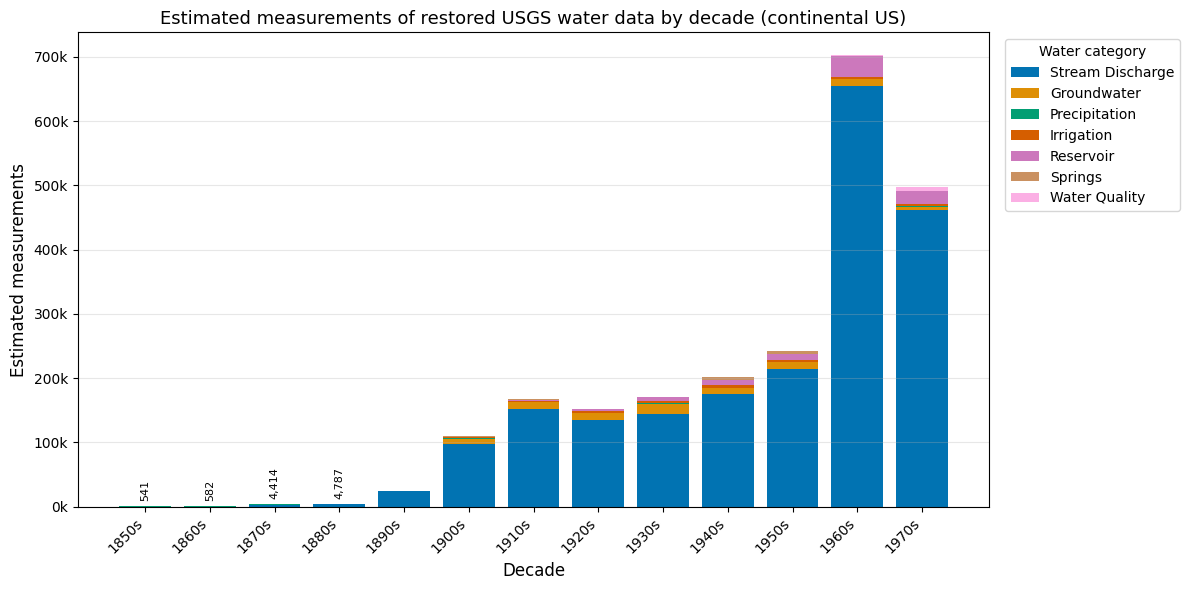

Saved measurements_by_type_decade.png


In [3]:
fig, ax = plt.subplots(figsize=(12, 6))

decades = pivot.index.astype(int)
x = np.arange(len(decades))
bar_width = 0.8
bottom = np.zeros(len(decades))

for wtype in pivot.columns:
    vals = pivot[wtype].values
    color = get_color_for(wtype)
    bars = ax.bar(x, vals, bar_width, bottom=bottom, color=color, label=wtype)

    bottom = bottom + vals

# early decades are too small to see: label each with its total
for i, tot in enumerate(pivot.sum(axis=1).values):
    if tot < 20000:
        ax.text(x[i], tot + 8000, f'{int(tot):,}', ha='center', va='bottom', fontsize=8, rotation=90)

ax.set_xticks(x)
ax.set_xticklabels([f'{int(d)}s' for d in decades], rotation=45, ha='right')
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f'{v/1e6:.1f}M' if v >= 1e6 else f'{v/1e3:.0f}k'))
ax.set_xlabel('Decade', fontsize=12)
ax.set_ylabel('Estimated measurements', fontsize=12)
ax.set_title('Estimated measurements of restored USGS water data by decade (continental US)', fontsize=13)
ax.legend(title='Water category', bbox_to_anchor=(1.01, 1), loc='upper left', fontsize=10)
ax.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.savefig(figures_path / 'measurements_by_type_decade.png', dpi=300, bbox_inches='tight')
plt.show()
print('Saved measurements_by_type_decade.png')